In [108]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.nn import functional as F
from torch.optim import Adam

In [18]:
class BasicNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.w00 = nn.Parameter(torch.tensor(1.7), requires_grad=False)
        self.b00 = nn.Parameter(torch.tensor(-0.85), requires_grad=False)
        self.w01 = nn.Parameter(torch.tensor(-40.8), requires_grad=False)

        self.w10 = nn.Parameter(torch.tensor(12.6), requires_grad=False)
        self.b10 = nn.Parameter(torch.tensor(0.0), requires_grad=False)
        self.w11 = nn.Parameter(torch.tensor(2.7), requires_grad=False)

        self.final_bias = nn.Parameter(torch.tensor(-16.), requires_grad=False)

    def forward(self, input):
        input_to_top_relu = input * self.w00 + self.b00
        tob_relu_output = F.relu(input_to_top_relu)
        scaled_top_relu_output = tob_relu_output * self.w01

        input_to_bottom_relu = input * self.w10 + self.b10
        bottom_relu_output = F.relu(input_to_bottom_relu)
        scaled_bottom_relu_output = bottom_relu_output * self.w11

        input_to_final_relu = scaled_top_relu_output + scaled_bottom_relu_output + self.final_bias

        output = F.relu(input_to_final_relu)
        return output


In [12]:
input_doses = torch.linspace(start=0, end=1, steps=11)
input_doses

tensor([0.0000, 0.1000, 0.2000, 0.3000, 0.4000, 0.5000, 0.6000, 0.7000, 0.8000,
        0.9000, 1.0000])

Text(0.5, 0, 'Dose')

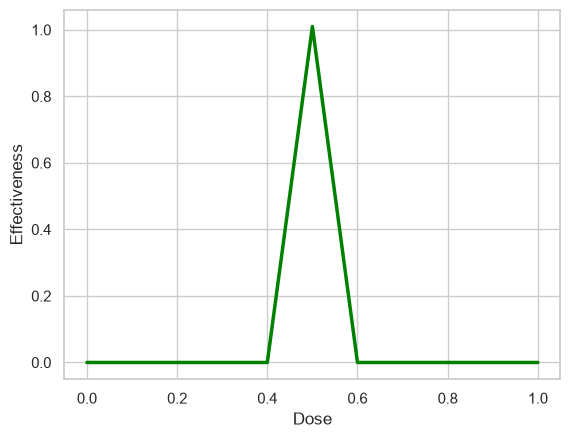

In [23]:
model = BasicNN()
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values,
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

In [164]:
class BasicNN_train(nn.Module):

    def __init__(self):
        super().__init__()

        # First neuron
        self.w00 = nn.Parameter(torch.randn(()))
        self.b00 = nn.Parameter(torch.randn(()))
        self.w01 = nn.Parameter(torch.randn(()))

        # Second neuron
        self.w10 = nn.Parameter(torch.randn(()))
        self.b10 = nn.Parameter(torch.randn(()))
        self.w11 = nn.Parameter(torch.randn(()))

        # Third neuron
        self.w20 = nn.Parameter(torch.randn(()))
        self.b20 = nn.Parameter(torch.randn(()))
        self.w21 = nn.Parameter(torch.randn(()))

        # Fourth neuron
        self.w30 = nn.Parameter(torch.randn(()))
        self.b30 = nn.Parameter(torch.randn(()))
        self.w31 = nn.Parameter(torch.randn(()))

        # Output neuron bias
        self.final_bias = nn.Parameter(torch.tensor(0.1))

            # Initialize useful transition points
        with torch.no_grad():
            for i, point in enumerate([0.25, 0.4, 0.5, 0.6]):
                w = torch.rand(()) + 0.5
                transition = point + (torch.rand(()) - 0.5) * 0.06

                getattr(self, f"w{i}0").copy_(w)
                getattr(self, f"b{i}0").copy_(-w * transition)

    def forward(self, input):

        # First neuron
        input_to_relu_0 = input * self.w00 + self.b00
        relu_output_0 = F.leaky_relu(input_to_relu_0)
        scaled_relu_output_0 = relu_output_0 * self.w01

        # Second neuron
        input_to_relu_1 = input * self.w10 + self.b10
        relu_output_1 = F.leaky_relu(input_to_relu_1)
        scaled_relu_output_1 = relu_output_1 * self.w11

        # Third neuron
        input_to_relu_2 = input * self.w20 + self.b20
        relu_output_2 = F.leaky_relu(input_to_relu_2)
        scaled_relu_output_2 = relu_output_2 * self.w21

        # Fourth neuron
        input_to_relu_3 = input * self.w30 + self.b30
        relu_output_3 = F.leaky_relu(input_to_relu_3)
        scaled_relu_output_3 = relu_output_3 * self.w31

        # Output neuron
        input_to_final_relu = (
            scaled_relu_output_0
            + scaled_relu_output_1
            + scaled_relu_output_2
            + scaled_relu_output_3
            + self.final_bias
        )

        output = input_to_final_relu

        return output

Text(0.5, 0, 'Dose')

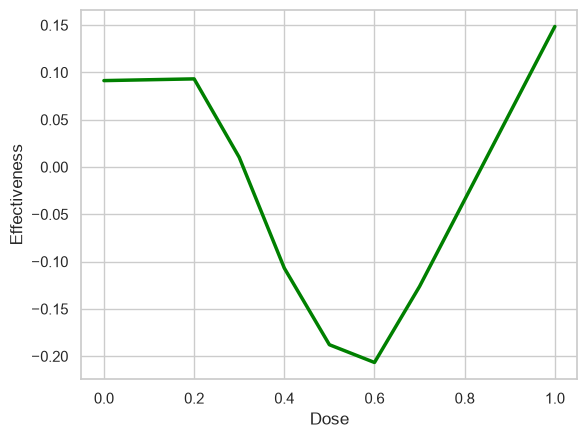

In [158]:
model = BasicNN_train()
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

In [162]:
torch.manual_seed(42)

inputs = torch.linspace(0, 1, 101)

labels = torch.clamp(
    1 - 10 * torch.abs(inputs - 0.5),
    min=0
)

model = BasicNN_train()

optimizer = Adam(model.parameters(), lr=0.1)
loss_history = []
print(f"Final bias, before optimization: {str(model.final_bias.data)} \n")

for epoch in range(1000):
    total_loss = 0

    for iteration in range(len(inputs)):
        input_i = inputs[iteration]
        label_i = labels[iteration]

        output_i = model(input_i)

        loss = (output_i - label_i) ** 2

        loss.backward()

        total_loss += float(loss)

    loss_history.append(total_loss)

    if total_loss < 0.0001:
        print(f"Num steps: {str(epoch)}")
        break

    optimizer.step()
    optimizer.zero_grad()

    print(f"Step: {str(epoch)} Final Bias: {str(model.final_bias.data)} \n")

print(f"Final bias, after optimization: {str(model.final_bias.data)}")

Final bias, before optimization: tensor(0.1000) 

Step: 0 Final Bias: tensor(1.4901e-08) 

Step: 1 Final Bias: tensor(-0.0230) 

Step: 2 Final Bias: tensor(0.0074) 

Step: 3 Final Bias: tensor(0.0577) 

Step: 4 Final Bias: tensor(0.1132) 

Step: 5 Final Bias: tensor(0.1632) 

Step: 6 Final Bias: tensor(0.1993) 

Step: 7 Final Bias: tensor(0.2173) 

Step: 8 Final Bias: tensor(0.2178) 

Step: 9 Final Bias: tensor(0.2039) 

Step: 10 Final Bias: tensor(0.1797) 

Step: 11 Final Bias: tensor(0.1491) 

Step: 12 Final Bias: tensor(0.1160) 

Step: 13 Final Bias: tensor(0.0843) 

Step: 14 Final Bias: tensor(0.0574) 

Step: 15 Final Bias: tensor(0.0380) 

Step: 16 Final Bias: tensor(0.0278) 

Step: 17 Final Bias: tensor(0.0270) 

Step: 18 Final Bias: tensor(0.0345) 

Step: 19 Final Bias: tensor(0.0487) 

Step: 20 Final Bias: tensor(0.0674) 

Step: 21 Final Bias: tensor(0.0879) 

Step: 22 Final Bias: tensor(0.1079) 

Step: 23 Final Bias: tensor(0.1249) 

Step: 24 Final Bias: tensor(0.1372) 

Step:

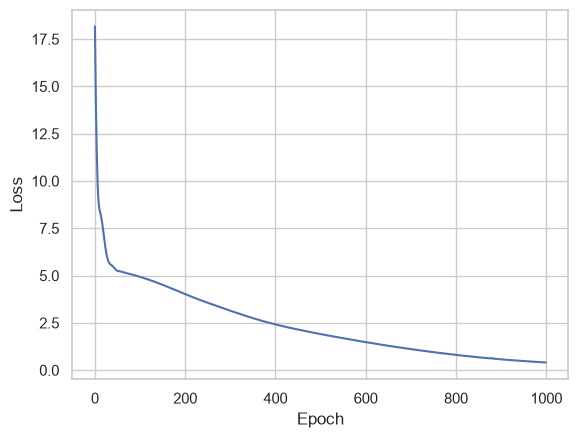

In [160]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

Text(0.5, 0, 'Dose')

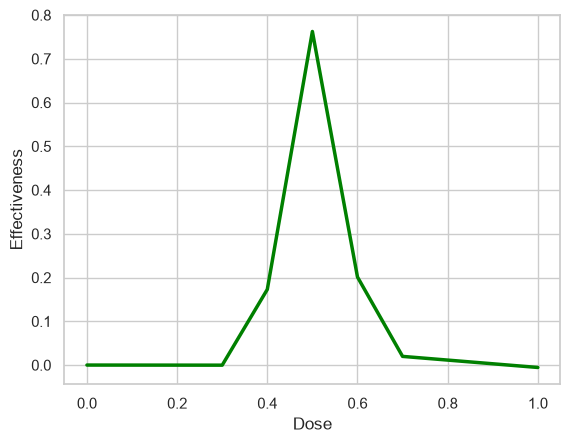

In [161]:
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

Strong Model

In [171]:
class BasicNN_train_strong(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(1, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 32)

        self.output = nn.Linear(32, 1)

        # Random Kaiming initialization
        for layer in [self.fc1, self.fc2, self.fc3, self.fc4]:

            nn.init.kaiming_normal_(
                layer.weight,
                a=0.1,
                nonlinearity="leaky_relu"
            )

        # Output layer initialization
        nn.init.xavier_uniform_(self.output.weight)

    def forward(self, x):

        x = x.reshape(-1, 1)

        x = F.leaky_relu(self.fc1(x), negative_slope=0.1)
        x = F.leaky_relu(self.fc2(x), negative_slope=0.1)
        x = F.leaky_relu(self.fc3(x), negative_slope=0.1)
        x = F.leaky_relu(self.fc4(x), negative_slope=0.1)

        x = self.output(x)

        return x.squeeze(-1)

Text(0.5, 0, 'Dose')

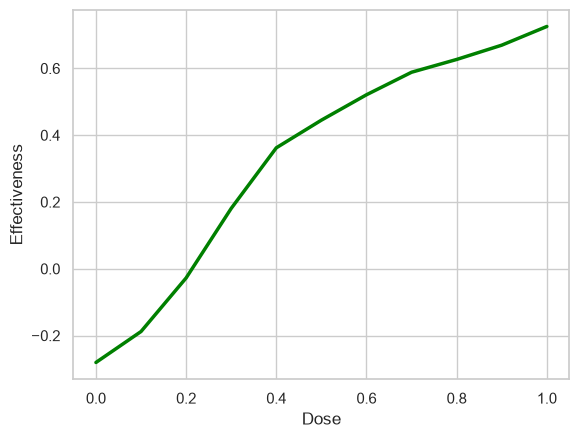

In [172]:
model = BasicNN_train_strong()
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")

In [176]:
torch.manual_seed(42)

inputs = torch.linspace(0, 1, 101)

labels = torch.clamp(
    1 - 10 * torch.abs(inputs - 0.5),
    min=0
)

model = BasicNN_train_strong()

optimizer = Adam(model.parameters(), lr=0.01)
loss_history = []

for epoch in range(1000):
    total_loss = 0

    for iteration in range(len(inputs)):
        input_i = inputs[iteration]
        label_i = labels[iteration]

        output_i = model(input_i)

        loss = (output_i - label_i) ** 2

        loss.backward()

        total_loss += float(loss)

    loss_history.append(total_loss)

    if total_loss < 0.0001:
        print(f"Num steps: {str(epoch)}")
        break

    optimizer.step()
    optimizer.zero_grad()

    print(f"Step: {str(epoch)} total loss: {str(total_loss)} \n")

print(f"Final bias, after optimization: {str(total_loss)}")

Step: 0 total loss: 73.61055487889098 

Step: 1 total loss: 863.8830889463425 

Step: 2 total loss: 58.53188228607178 

Step: 3 total loss: 13.226412467320642 

Step: 4 total loss: 54.94658237142903 

Step: 5 total loss: 6.23756999248144 

Step: 6 total loss: 27.94246314279735 

Step: 7 total loss: 6.176897242607083 

Step: 8 total loss: 21.916362298245076 

Step: 9 total loss: 5.755887111736229 

Step: 10 total loss: 18.141779395518824 

Step: 11 total loss: 8.025402122786048 

Step: 12 total loss: 10.653608711145353 

Step: 13 total loss: 12.355090882978402 

Step: 14 total loss: 5.635792281356835 

Step: 15 total loss: 12.858993712507072 

Step: 16 total loss: 6.606893530672551 

Step: 17 total loss: 8.503543451427504 

Step: 18 total loss: 9.558595912571036 

Step: 19 total loss: 5.224881283256764 

Step: 20 total loss: 9.35724871375018 

Step: 21 total loss: 6.073803986931068 

Step: 22 total loss: 6.712441690940977 

Step: 23 total loss: 7.5709221897304815 

Step: 24 total loss: 

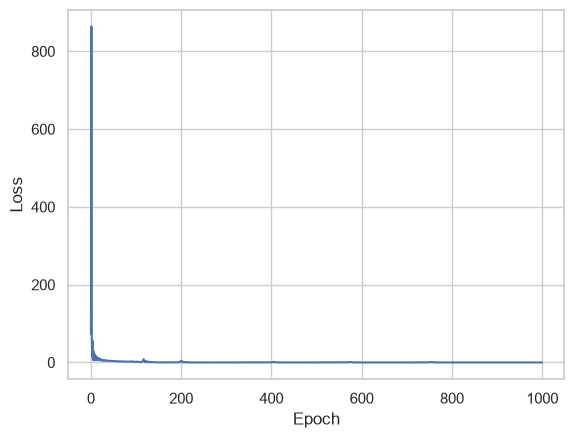

In [177]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

Text(0.5, 0, 'Dose')

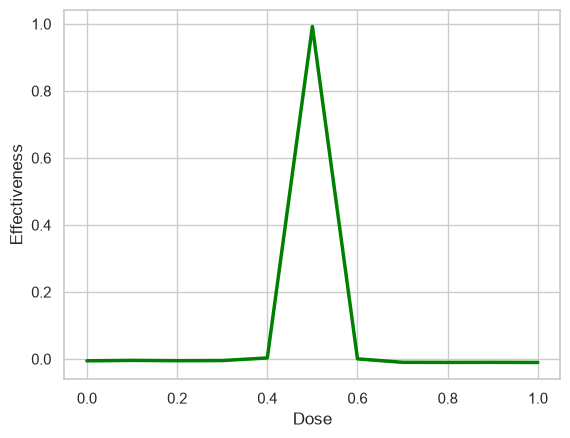

In [178]:
output_values = model(input_doses)

sns.set(style="whitegrid")
sns.lineplot(x=input_doses,
             y=output_values.detach(),
             color="green",
             linewidth=2.5)

plt.ylabel("Effectiveness")
plt.xlabel("Dose")